In [6]:
# data generation logic
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

pd.set_option('display.max_columns' , None)
pd.set_option('display.max_rows' , None)

print(df)
# df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
5           NaN   89.040509      55.932624    40.751177
6      8.158426  103.861859      77.725529    57.171201
7      6.534869   86.745778      77.706789    41.874669
8      4.061051   87.575504      77.725715    46.583807
9      6.085120   84.255541     127.790972    52.866454
10     4.073165   65.812288      78.563358    36.404534
11     4.068540   84.734861      87.033485    50.355310
12     5.483925   85.602302      84.310026    49.411740
13     1.173440  109.632421      79.770869    53.498168
14     1.550164   83.076390      65.270961    45.279586
15     3.875425   88.015473      81.384538    44.724281
16     2.974338   84.652882      58.407622    41

<Axes: >

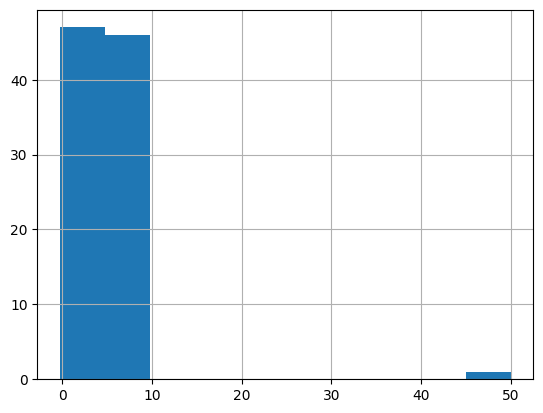

In [7]:
# A . Identify the outlier in study_hours and remove or cap this value
df['study_hours'].hist()

In [8]:
df.describe()

,study_hours,attendance,previous_mark,final_score
count,94.000000,100.000000,100.000000,100.000000
mean,5.218916,84.267225,70.973444,42.691957
std,5.014751,13.476443,16.264243,6.086797
min,-0.239490,-10.000000,21.380990,29.163251
25%,3.731467,76.829717,60.168347,38.188854
50%,4.812342,85.841072,71.465436,42.763014
75%,5.744365,90.381704,80.566562,46.688328
max,50.000000,112.201692,127.790972,57.171201


In [9]:
df[df['study_hours'] == 50]

,study_hours,attendance,previous_mark,final_score
99,50.0,73.570297,79.444433,46.41447


In [10]:
# so as we can see the outlier is the student with 50 study hours , while the mean for the 
# study hours is 5 hours , since that student is the only one with 50 hours in the study
# it doesn't make sense . Thus I have decided to make the data to have a value of 5 assuming it is a type error
# because all the other things are normal.

# df.loc[ reference , the_column ] = new_val

df.loc[df['study_hours'] == 50 , 'study_hours'] = 5

In [11]:
df[df['study_hours'] == 50] # checking

,study_hours,attendance,previous_mark,final_score


In [12]:
# here when assessing the feature matrix which includes the feature elements and
# the target element we see there are 100 rows and 4 columns 
# in Identifying feature and target elements
# feature elements here are study_hours,attendance	previous_mark 
# the final_score would be the target element
# And all of the columns are numerical
print(df.shape)

(100, 4)


In [13]:
# B. Summarizing the data
df.describe()
# this function will calculate the mean , median (Q2) and standard deviation

# Observations

# Observation A. The mean for previous marks is 70 while Q3 is 80 , which means most data points are 
# below 80 and there is a concentration there.









,study_hours,attendance,previous_mark,final_score
count,94.000000,100.000000,100.000000,100.000000
mean,4.740193,84.267225,70.973444,42.691957
std,1.831325,13.476443,16.264243,6.086797
min,-0.239490,-10.000000,21.380990,29.163251
25%,3.731467,76.829717,60.168347,38.188854
50%,4.812342,85.841072,71.465436,42.763014
75%,5.723152,90.381704,80.566562,46.688328
max,8.704556,112.201692,127.790972,57.171201


<Axes: ylabel='Frequency'>

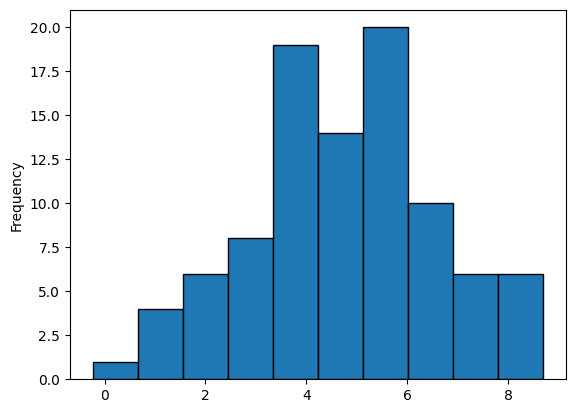

In [25]:
# Observation B. The study hour has the lowest standard deviation of the 4 indicating most students
# study_hours is closer to the mean which is around 4.7 and is consistent.

df['study_hours'].plot(kind='hist' , edgecolor='black')
# as seen below the mean is 4.7 and the frequency count for the bin around 4.7 is high
# indicating that most data points are distributed around that

<Axes: ylabel='Frequency'>

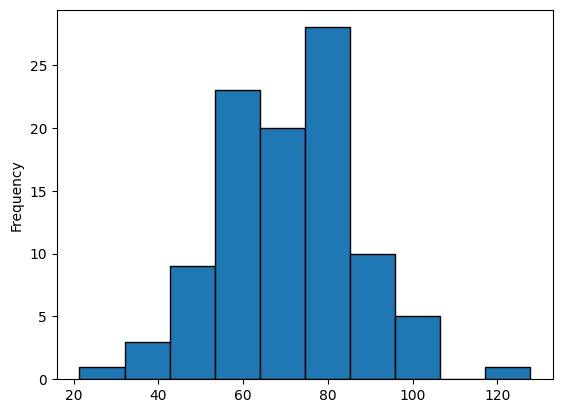

In [26]:
df['previous_mark'].plot(kind='hist' , edgecolor='black')

<Axes: ylabel='Frequency'>

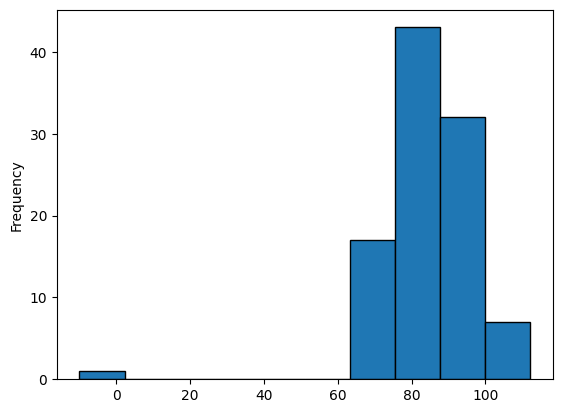

In [27]:
# Observation C. The mean and median for the attendance are almost equal which implies the absense
# of too many outliers pulling the data in attendance.

df['attendance'].plot(kind='hist' , edgecolor='black')

<Axes: ylabel='Frequency'>

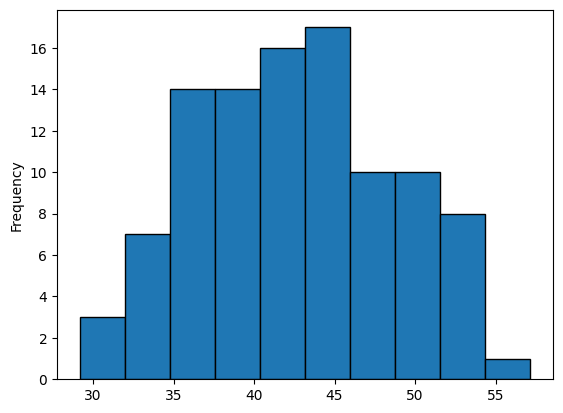

In [28]:
# C. Visualize
# histogram for final score
df['final_score'].plot(kind='hist' , edgecolor='black')


<Axes: xlabel='study_hours', ylabel='final_score'>

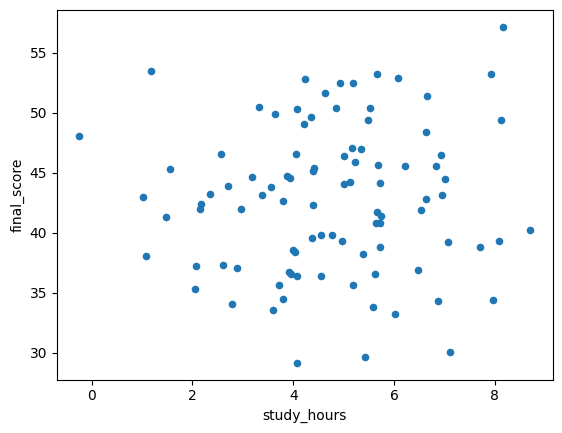

In [29]:
# scatter plot  - study_hours vs final_score
df.plot(kind='scatter' , x='study_hours' , y='final_score')
# this part explains about the relationship between study hours and final_score
# in the bottom right it shows that sometimes when study hrs increase the final score
# decreases and also sometimes it increases as seen in the top right
# but considering most part of the data points which are located in the middle
# I would say the people who studied between 4 - 6 hours got relatively higher
# output from their study time because their data points scored the higher collective
# value. There are outliers in this relationship of people studying less than 0 hours and 
# less than 2 hours still scoring good final_score but the middle is the one that shows
# the general trend.


In [31]:
# D . Correlation and Causality
# Pearson's correlation coeficient will tell us how 2 values are correlated
df['study_hours'].corr(df['final_score'])
# seeing the result we can say there is a weak correlation between study hours and 
# final score because the value is 0.05

# A student studies 10 hours , does the correlation guarantee a specific score?
# Not really because the correlation coeficient is 0.05 between the two which means
# we can't say something about one seeing the other.
# I think the confoundinf variable that will relate to both may be the concentration
# during their study. Because concentration may affect both the study hour and final score
# if someone studies with concentration they may not need as much study hour but still can be 
# effective in their final score.





np.float64(0.052038262141665154)

In [54]:
# E . Vector and dot product
# select a data point without the target 
# weight vector and bias
selectedScore = df[df['study_hours'].round(6) == 5.628495]
updatedScore = selectedScore.drop(columns=['final_score']).to_numpy().flatten()
# print(updatedScore)
# drop the final_score and change it to final_score
weight = np.array([0.5, 0.2, 0.4])
bias = 5.0
# print(weight)

y = np.dot(weight , updatedScore) + bias
print(y)


# The weight matrix represents the effect of each feature in predicting the target
# which is the final_score. Thus we can say the final score is affected by study_hours
# 50 % and 20 % by attendance and 40 % by previous_marks.
# The need for bias is so that if the dot product is 0 then the prediction will be 0
# to avoid that we will shift the predicted value up by some number.



49.05597961691616


In [60]:
# F. Scaling

# we have to drop Nan columns because they ruin the study_hours in here
df = df.dropna(subset=['study_hours'])

mean_study = df['study_hours'].mean() # select the mean and standard deviation
print(mean_study)
# standardizing the mean 
std_study = df['study_hours'].std()
print(std_study)
# to standardize the data , data - mean / std

df['study_hours_scaled'] = (df['study_hours'] - mean_study) / std_study

# print(df)


# standardize the previous_mark 
mean_mark = df['previous_mark'].mean()
std_mark = df['previous_mark'].std()
df['previous_mark_scaled'] = (df['previous_mark'] - mean_mark) / std_mark

# Preview the scaled columns
print(df[['study_hours_scaled', 'previous_mark_scaled']].head())

# The reason why distance based algorithms fail is because they are influenced by one 
# dominant feature in this case the previous_mark which will make the study_hours useless.
# This is because the range for previous_mark is greater than range for study_hours.


4.7401927123253085
1.831325297946749
    study_hours_scaled  previous_mark_scaled
6             1.866535              0.415521
7             0.979988              0.414378
8            -0.370847              0.415533
9             0.734401              3.471220
10           -0.364232              0.466658
